Problem-03

Using Python and scikit-learn, generate a binary classification dataset with 500 observations, 6 features, 4 informative features, 1 redundant feature, 2 classes and random_state = last two digits of your roll number

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score,ConfusionMatrixDisplay


In [9]:
# (a) Generate the dataset
X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=1,  
    n_classes=2,
    random_state=42
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Define three classifiers
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=35),
    'Gaussian Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

# Store AUC scores
results = []

In [10]:
# (b) Train the model
for name,model in models.items():
    model.fit(X_train,y_train)
    y_prob=model.predict_proba(X_test)[:,1]
    y_pred = model.predict(X_test)


Model: KNN
Confusion Matrix:
[[63 12]
 [16 59]]


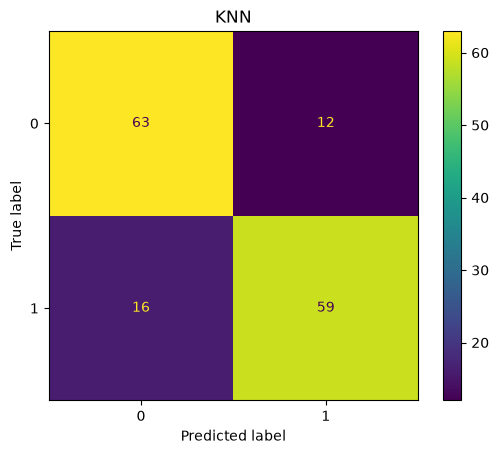

In [11]:
# (c) Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nModel:", name)
print("Confusion Matrix:")
print(cm)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
).plot()
plt.title(name)
plt.show()


In [12]:
# (d) ROC-AUC score
auc = roc_auc_score(y_test, y_pred)
print("ROC-AUC Score:", round(auc, 4))
# Store results
results.append({
    'Model': name,
    'AUC': auc
})

ROC-AUC Score: 0.8133


In [13]:
# (e) Compare models
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    by='AUC', ascending=False
).reset_index(drop=True)
print(comparison)

  Model       AUC
0   KNN  0.813333


In [14]:
best_model = comparison.loc[0]
print("Best Model:", best_model)

Best Model: Model         KNN
AUC      0.813333
Name: 0, dtype: object


Interpretation of Problem 2: Model Comparison
Among the classification models, K-Nearest Neighbors (KNN) achieved the highest AUC value of 0.8133, indicating good ability to distinguish between the two classes. The confusion matrix shows that the model correctly classified 63 negative cases and 59 positive cases. However, it incorrectly classified 12 negative cases as positive and 16 positive cases as negative. Overall, KNN demonstrated good classification performance and was selected as the best model based on its AUC value.